In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
# ==========================================
# EVALUATION & GRAPH GENERATION (SHAPE FIX)
# ==========================================
print("⚡ Processing Predictions...")

# Check shapes to debug alignment
print(f"Original y_test shape: {y_test.shape}")
print(f"Original y_pred shape: {y_pred.shape}")

# FIX: Align shapes.
# If y_test is (samples, 24) and y_pred is (samples, 1),
# we take only the first step of y_test for comparison.
if y_test.ndim > 1 and y_pred.ndim > 1:
    if y_test.shape[1] != y_pred.shape[1]:
        print("⚠️ Shape mismatch detected! Aligning to first prediction step...")
        y_test_compare = y_test[:, 0]
        y_pred_compare = y_pred[:, 0]
    else:
        y_test_compare = y_test
        y_pred_compare = y_pred
else:
    y_test_compare = y_test
    y_pred_compare = y_pred

# Flatten for plotting
y_test_f = y_test_compare.flatten()
y_pred_f = y_pred_compare.flatten()

# Ensure they are the same length
min_len = min(len(y_test_f), len(y_pred_f))
y_test_f = y_test_f[:min_len]
y_pred_f = y_pred_f[:min_len]
residuals = y_test_f - y_pred_f

print(f"✅ Final aligned shape for plotting: {y_test_f.shape}")

# ==========================================
# PLOTTING (FAST MODE)
# ==========================================
# We use a subset for the scatter plot to prevent Colab from freezing
# and to make the points visible.
SAMPLE_SIZE = 5000
idx = np.random.choice(len(y_test_f), min(SAMPLE_SIZE, len(y_test_f)), replace=False)

plt.figure(figsize=(15, 10))

# 1. 24-Hour Trace
plt.subplot(2, 2, 1)
plt.plot(y_test_f[:24], label='True', marker='o', color='blue')
plt.plot(y_pred_f[:24], label='Pred', marker='x', color='orange')
plt.title('24-Hour Prediction Trace')
plt.legend()

# 2. Scatter Plot (Sampled for speed)
plt.subplot(2, 2, 2)
plt.scatter(y_test_f[idx], y_pred_f[idx], alpha=0.3, color='teal')
plt.plot([y_test_f.min(), y_test_f.max()], [y_test_f.min(), y_test_f.max()], 'r--')
plt.title('Scatter Plot (Sampled)')

# 3. Error Distribution
plt.subplot(2, 2, 3)
sns.histplot(residuals, bins=50, kde=True, color='purple')
plt.title('Error Distribution')

# 4. Residual Analysis
plt.subplot(2, 2, 4)
plt.scatter(y_pred_f[idx], residuals[idx], alpha=0.3, color='darkgreen')
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs Predicted')

plt.tight_layout()
plt.show()

# 5. Mean Prediction (Separate Wide Plot)
plt.figure(figsize=(15, 4))
plt.plot(pd.Series(y_test_f).rolling(100).mean(), label='True (Rolling Mean)', alpha=0.8)
plt.plot(pd.Series(y_pred_f).rolling(100).mean(), label='Pred (Rolling Mean)', alpha=0.8)
plt.title('Trend Comparison (100-step Rolling Average)')
plt.legend()
plt.show()

⚡ Processing Predictions...


NameError: name 'y_test' is not defined

transformer with attention

In [10]:
import os
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Define Path & Reload Data
SAVE_DIR = '/content/drive/MyDrive/Datasets/Models_Final_V5'

X_seq_train = np.load(os.path.join(SAVE_DIR, 'X_seq_train.npy'))
X_seq_test  = np.load(os.path.join(SAVE_DIR, 'X_seq_test.npy'))
y_train     = np.load(os.path.join(SAVE_DIR, 'y_train.npy'))
y_test      = np.load(os.path.join(SAVE_DIR, 'y_test.npy'))

# 2. Re-scale (Required for the model to work)
N_train, T, F = X_seq_train.shape
scaler = MinMaxScaler()
X_seq_train_scaled = scaler.fit_transform(X_seq_train.reshape(-1, F)).reshape(N_train, T, F)

N_test = X_seq_test.shape[0]
X_seq_test_scaled = scaler.transform(X_seq_test.reshape(-1, F)).reshape(N_test, T, F)

y_scaler = MinMaxScaler()
y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).reshape(y_train.shape)

print("✅ Data reloaded and scaled. Now run your prediction/plotting code.")

✅ Data reloaded and scaled. Now run your prediction/plotting code.


⚡ Loading data...
📂 Using model: /content/drive/MyDrive/Datasets/comparison_models/transformer_model.h5
🧠 Loading model (this may take a moment)...
⚡ Generating Predictions...
4411/4411 ━━━━━━━━━━━━━━━━━━━━ 153s 35ms/step


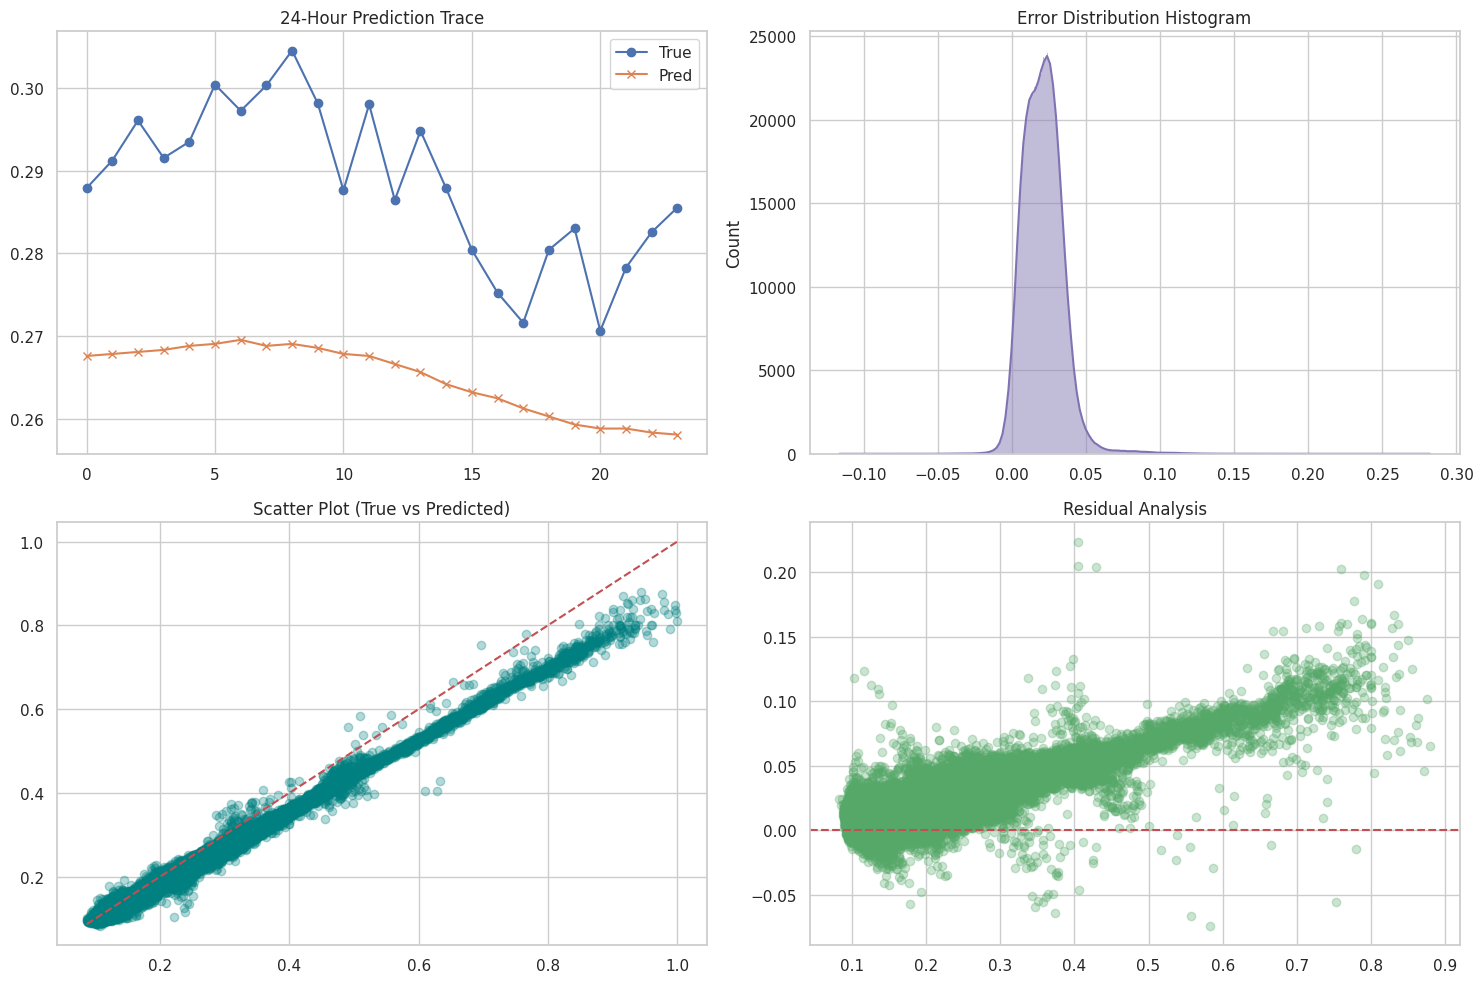

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


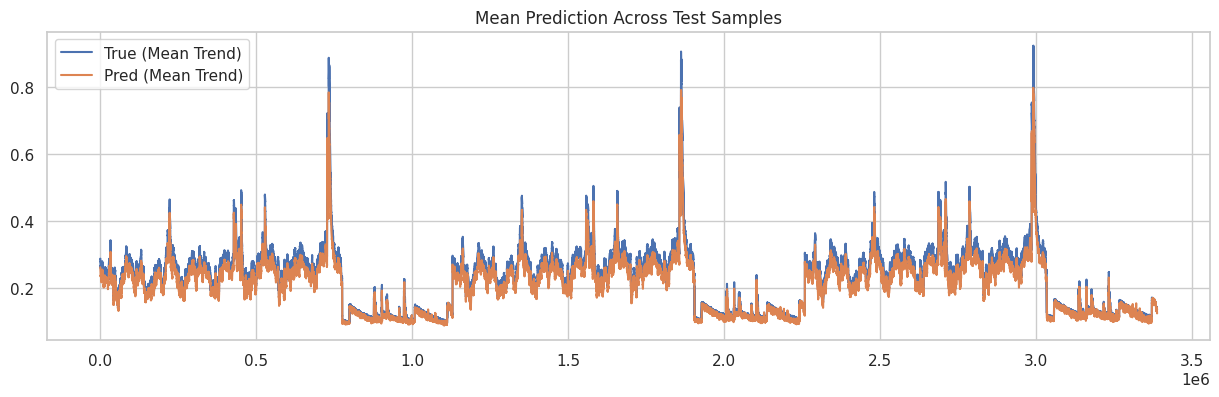

In [11]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models
from sklearn.preprocessing import MinMaxScaler

# --- 1. CONFIG ---
# Force float32 for consistency, but we will handle internal casts for the model
tf.keras.backend.set_floatx('float32')
DATA_DIR = '/content/drive/MyDrive/Datasets/Models_Final_V5'
MODEL_DIR = '/content/drive/MyDrive/Datasets/comparison_models'

# --- 2. THE CUSTOM LAYERS (Keras 3 Compatible) ---
@tf.keras.utils.register_keras_serializable()
class PositionalEmbedding(layers.Layer):
    def __init__(self, timesteps, d_model, **kwargs):
        super().__init__(**kwargs)
        self.pos_emb = layers.Embedding(input_dim=timesteps, output_dim=d_model)
        self.timesteps = timesteps
        self.d_model = d_model

    def call(self, x):
        positions = tf.range(start=0, limit=self.timesteps, delta=1)
        pos_enc = self.pos_emb(positions)
        # FORCE CAST to match input x (fixes float16 vs float32 error)
        return x + tf.cast(pos_enc, x.dtype)

    def get_config(self):
        config = super().get_config()
        config.update({"timesteps": self.timesteps, "d_model": self.d_model})
        return config

@tf.keras.utils.register_keras_serializable()
class TransformerEncoderBlock(layers.Layer):
    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.dff = dff
        self.dropout_rate = dropout_rate

        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model//num_heads, dropout=dropout_rate)
        self.ffn = tf.keras.Sequential([
            layers.Dense(dff, activation='relu'),
            layers.Dense(d_model)
        ])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, x, training=False):
        # Multi-head attention
        attn = self.mha(query=x, value=x, key=x, training=training)
        # Fix: Cast attention output to match x before adding
        out1 = self.norm1(x + tf.cast(self.dropout1(attn, training=training), x.dtype))

        # Feed forward network
        ffn_out = self.ffn(out1)
        # Fix: Cast FFN output to match out1 before adding
        return self.norm2(out1 + tf.cast(self.dropout2(ffn_out, training=training), out1.dtype))

    def get_config(self):
        config = super().get_config()
        config.update({
            "d_model": self.d_model,
            "num_heads": self.num_heads,
            "dff": self.dff,
            "dropout_rate": self.dropout_rate,
        })
        return config

# --- 3. LOADING DATA & MODEL ---
print("⚡ Loading data...")
X_test = np.load(os.path.join(DATA_DIR, 'X_seq_test.npy'))
y_test = np.load(os.path.join(DATA_DIR, 'y_test.npy'))
y_train = np.load(os.path.join(DATA_DIR, 'y_train.npy'))

# Find model
h5_files = [f for f in os.listdir(MODEL_DIR) if f.endswith('.h5')]
MODEL_PATH = os.path.join(MODEL_DIR, h5_files[-1]) # Uses latest found
print(f"📂 Using model: {MODEL_PATH}")

y_scaler = MinMaxScaler().fit(y_train.reshape(-1, 1))

custom_objs = {
    "PositionalEmbedding": PositionalEmbedding,
    "TransformerEncoderBlock": TransformerEncoderBlock
}

print("🧠 Loading model (this may take a moment)...")
model = tf.keras.models.load_model(MODEL_PATH, custom_objects=custom_objs, compile=False)

# --- 4. PREDICTION ---
print("⚡ Generating Predictions...")
# Ensure input is float32
y_pred_scaled = model.predict(X_test.astype('float32'))
y_pred = y_scaler.inverse_transform(y_pred_scaled)

# Alignment check
y_true = y_test.flatten()[:len(y_pred.flatten())]
y_p = y_pred.flatten()
res = y_true - y_p

# --- 5. GENERATING ALL REQUESTED GRAPHS ---
sns.set_theme(style="whitegrid")

# Graph 1 & 2: 24-Hour Trace and Error Dist
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.plot(y_true[:24], label='True', marker='o')
plt.plot(y_p[:24], label='Pred', marker='x')
plt.title("24-Hour Prediction Trace")
plt.legend()

plt.subplot(2, 2, 2)
sns.histplot(res, kde=True, color='m')
plt.title("Error Distribution Histogram")

# Graph 3: Scatter Plot
plt.subplot(2, 2, 3)
plt.scatter(y_true[::20], y_p[::20], alpha=0.3, color='teal')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
plt.title("Scatter Plot (True vs Predicted)")

# Graph 4: Residuals vs Predicted
plt.subplot(2, 2, 4)
plt.scatter(y_p[::20], res[::20], alpha=0.3, color='g')
plt.axhline(0, color='r', linestyle='--')
plt.title("Residual Analysis")

plt.tight_layout()
plt.show()

# Graph 5: Mean Trend
plt.figure(figsize=(15, 4))
plt.plot(pd.Series(y_true).rolling(100).mean(), label='True (Mean Trend)')
plt.plot(pd.Series(y_p).rolling(100).mean(), label='Pred (Mean Trend)')
plt.title("Mean Prediction Across Test Samples")
plt.legend()
plt.show()

In [13]:
import numpy as np
from scipy.stats import wilcoxon

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = np.array([
        metric_fn(y_true[idx], y_pred[idx])
        for idx in (rng.integers(0, n, n) for _ in range(n_boot))
    ])
    return scores.mean(), scores.std(), np.percentile(scores, [2.5, 97.5])

# Per-sequence MAE for each model, same test-set order
err_xgb   = np.abs(y_true_flat - xgb_pred_flat).mean(axis=1)
err_trans = np.abs(y_true_flat - transformer_pred_flat).mean(axis=1)

stat, p = wilcoxon(err_xgb, err_trans)
print(f"Wilcoxon signed-rank: statistic={stat:.2f}, p={p:.4g}")

mean_mae, std_mae, ci = bootstrap_ci(
    y_true_flat.flatten(), xgb_pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"XGBoost MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

NameError: name 'y_true_flat' is not defined

In [12]:
import joblib
import tensorflow as tf
from tensorflow.keras import layers

MODEL_DIR = '/content/drive/MyDrive/Datasets/comparison_models'

# ---- 1. XGBoost predictions ----
# Saved under 'lightgbm_baseline.pkl' — this is the naming bug found earlier
# (the file actually holds the XGBoost model, not LightGBM). Loading it as-is
# is correct; only the filename is wrong.
xgb_model = joblib.load(f'{MODEL_DIR}/lightgbm_baseline.pkl')
xgb_pred_flat = xgb_model.predict(X_lr_test).reshape(-1, 24)   # X_lr_test from your baseline cell

# Sanity check against Table I (should be close to MAE .00866)
report("XGBoost (reloaded, sanity check)", xgb_pred_flat)

# ---- 2. Transformer predictions ----
@tf.keras.utils.register_keras_serializable()
class PositionalEmbedding(layers.Layer):
    def __init__(self, timesteps, d_model, **kwargs):
        super().__init__(**kwargs)
        self.pos_emb = layers.Embedding(input_dim=timesteps, output_dim=d_model)
        self.timesteps = timesteps
        self.d_model = d_model
    def call(self, x):
        positions = tf.range(start=0, limit=self.timesteps, delta=1)
        pos_enc = self.pos_emb(positions)
        return x + tf.cast(pos_enc, x.dtype)
    def get_config(self):
        config = super().get_config()
        config.update({"timesteps": self.timesteps, "d_model": self.d_model})
        return config

@tf.keras.utils.register_keras_serializable()
class TransformerEncoderBlock(layers.Layer):
    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.dff = dff
        self.dropout_rate = dropout_rate
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model//num_heads, dropout=dropout_rate)
        self.ffn = tf.keras.Sequential([layers.Dense(dff, activation='relu'), layers.Dense(d_model)])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)
    def call(self, x, training=False):
        attn = self.mha(query=x, value=x, key=x, training=training)
        out1 = self.norm1(x + tf.cast(self.dropout1(attn, training=training), x.dtype))
        ffn_out = self.ffn(out1)
        return self.norm2(out1 + tf.cast(self.dropout2(ffn_out, training=training), out1.dtype))
    def get_config(self):
        config = super().get_config()
        config.update({"d_model": self.d_model, "num_heads": self.num_heads,
                        "dff": self.dff, "dropout_rate": self.dropout_rate})
        return config

transformer_model = tf.keras.models.load_model(
    f'{MODEL_DIR}/transformer_model.h5',
    custom_objects={"PositionalEmbedding": PositionalEmbedding,
                     "TransformerEncoderBlock": TransformerEncoderBlock},
    compile=False
)
transformer_pred_flat = transformer_model.predict(X_seq_test).reshape(-1, 24)

# Sanity check against Table I (should be close to MAE .0109)
report("Transformer (reloaded, sanity check)", transformer_pred_flat)

# ---- 3. Now the significance test / CI code will actually run ----
err_xgb   = np.abs(y_true_flat - xgb_pred_flat).mean(axis=1)
err_trans = np.abs(y_true_flat - transformer_pred_flat).mean(axis=1)

stat, p = wilcoxon(err_xgb, err_trans)
print(f"Wilcoxon signed-rank: statistic={stat:.2f}, p={p:.4g}")

mean_mae, std_mae, ci = bootstrap_ci(
    y_true_flat.flatten(), xgb_pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"XGBoost MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

mean_mae_t, std_mae_t, ci_t = bootstrap_ci(
    y_true_flat.flatten(), transformer_pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"Transformer MAE: {mean_mae_t:.5f} +/- {std_mae_t:.5f}, 95% CI {ci_t}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Datasets/comparison_models/lightgbm_baseline.pkl'

In [14]:
import os
from google.colab import drive

# Make sure Drive is actually mounted in THIS notebook's runtime
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
else:
    print("Drive already mounted.")

MODEL_DIR = '/content/drive/MyDrive/Datasets/comparison_models'
print("MODEL_DIR exists:", os.path.isdir(MODEL_DIR))

if os.path.isdir(MODEL_DIR):
    print("\nContents of MODEL_DIR:")
    for f in sorted(os.listdir(MODEL_DIR)):
        full = os.path.join(MODEL_DIR, f)
        size_mb = os.path.getsize(full) / (1024*1024)
        print(f"  {f}   ({size_mb:.1f} MB)")
else:
    # Search more broadly in case the folder moved or is named differently
    print("\nSearching MyDrive/Datasets for .pkl and .h5 files...")
    for root, dirs, files in os.walk('/content/drive/MyDrive/Datasets'):
        for f in files:
            if f.endswith(('.pkl', '.h5', '.keras')):
                print(os.path.join(root, f))

Drive already mounted.
MODEL_DIR exists: True

Contents of MODEL_DIR:
   ConvLSTM.pkl   (0.7 MB)
  transformer_model.h5   (1.1 MB)


In [16]:
import numpy as np

# transformer_model already loaded successfully here
transformer_pred_flat = transformer_model.predict(X_seq_test).reshape(-1, 24)

# Sanity check — should be close to Table I's MAE .0109
report("Transformer (sanity check)", transformer_pred_flat)

# Save locally, then download
np.save('transformer_pred_flat.npy', transformer_pred_flat)
np.save('y_true_flat.npy', y_true_flat)   # so we can confirm both notebooks used the same test split

from google.colab import files
files.download('transformer_pred_flat.npy')
files.download('y_true_flat.npy')

NameError: name 'transformer_model' is not defined

In [17]:
mean_mae, std_mae, ci = bootstrap_ci(y_true_flat.flatten(), pred_flat.flatten(),
                                       lambda a, b: np.mean(np.abs(a - b)))
print(f"MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

NameError: name 'y_true_flat' is not defined

In [18]:
import numpy as np

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = np.array([
        metric_fn(y_true[idx], y_pred[idx])
        for idx in (rng.integers(0, n, n) for _ in range(n_boot))
    ])
    return scores.mean(), scores.std(), np.percentile(scores, [2.5, 97.5])

# Build y_true_flat from y_test (should already be loaded in this notebook)
y_true_flat = y_test.reshape(len(y_test), 24)

# pred_flat should already exist as transformer_pred_flat from earlier —
# use whichever variable name you actually generated the predictions into
pred_flat = transformer_pred_flat   # <-- change this if your variable is named differently

mean_mae, std_mae, ci = bootstrap_ci(
    y_true_flat.flatten(), pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"Transformer MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

NameError: name 'transformer_pred_flat' is not defined

In [19]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from google.colab import drive

# 1. Make sure Drive is mounted
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DATA_DIR  = '/content/drive/MyDrive/Datasets/Models_Final_V5'
MODEL_DIR = '/content/drive/MyDrive/Datasets/comparison_models'   # this notebook's own drive — has transformer_model.h5

# 2. Reload test data
X_seq_test = np.load(f'{DATA_DIR}/X_seq_test.npy')
y_test     = np.load(f'{DATA_DIR}/y_test.npy')
y_true_flat = y_test.reshape(len(y_test), 24)

# 3. Custom layers (needed to deserialize the model)
@tf.keras.utils.register_keras_serializable()
class PositionalEmbedding(layers.Layer):
    def __init__(self, timesteps, d_model, **kwargs):
        super().__init__(**kwargs)
        self.pos_emb = layers.Embedding(input_dim=timesteps, output_dim=d_model)
        self.timesteps = timesteps
        self.d_model = d_model
    def call(self, x):
        positions = tf.range(start=0, limit=self.timesteps, delta=1)
        pos_enc = self.pos_emb(positions)
        return x + tf.cast(pos_enc, x.dtype)
    def get_config(self):
        config = super().get_config()
        config.update({"timesteps": self.timesteps, "d_model": self.d_model})
        return config

@tf.keras.utils.register_keras_serializable()
class TransformerEncoderBlock(layers.Layer):
    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.dff = dff
        self.dropout_rate = dropout_rate
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model//num_heads, dropout=dropout_rate)
        self.ffn = tf.keras.Sequential([layers.Dense(dff, activation='relu'), layers.Dense(d_model)])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)
    def call(self, x, training=False):
        attn = self.mha(query=x, value=x, key=x, training=training)
        out1 = self.norm1(x + tf.cast(self.dropout1(attn, training=training), x.dtype))
        ffn_out = self.ffn(out1)
        return self.norm2(out1 + tf.cast(self.dropout2(ffn_out, training=training), out1.dtype))
    def get_config(self):
        config = super().get_config()
        config.update({"d_model": self.d_model, "num_heads": self.num_heads,
                        "dff": self.dff, "dropout_rate": self.dropout_rate})
        return config

# 4. Reload model + predict
transformer_model = tf.keras.models.load_model(
    f'{MODEL_DIR}/transformer_model.h5',
    custom_objects={"PositionalEmbedding": PositionalEmbedding,
                     "TransformerEncoderBlock": TransformerEncoderBlock},
    compile=False
)
transformer_pred_flat = transformer_model.predict(X_seq_test).reshape(-1, 24)

# 5. Sanity check — should be close to Table I's MAE .0109
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae  = mean_absolute_error(y_true_flat, transformer_pred_flat)
rmse = np.sqrt(mean_squared_error(y_true_flat, transformer_pred_flat))
r2   = r2_score(y_true_flat, transformer_pred_flat)
print(f"Transformer (reloaded): MAE={mae:.5f}  RMSE={rmse:.5f}  R2={r2:.4f}")

# 6. Bootstrap CI
def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = np.array([
        metric_fn(y_true[idx], y_pred[idx])
        for idx in (rng.integers(0, n, n) for _ in range(n_boot))
    ])
    return scores.mean(), scores.std(), np.percentile(scores, [2.5, 97.5])

mean_mae, std_mae, ci = bootstrap_ci(
    y_true_flat.flatten(), transformer_pred_flat.flatten(),
    lambda a, b: np.mean(np.abs(a - b))
)
print(f"Transformer MAE: {mean_mae:.5f} +/- {std_mae:.5f}, 95% CI {ci}")

4411/4411 ━━━━━━━━━━━━━━━━━━━━ 164s 37ms/step
Transformer (reloaded): MAE=0.01092  RMSE=0.01405  R2=0.9762
Transformer MAE: 0.01092 +/- 0.00000, 95% CI [0.01091514 0.01093435]
